# KLUE-RoBERTa 기반 한국어 문서 질의응답

## 프로젝트 목표

사용자가 문단과 질문을 입력하면 **문단 안의 답변 구절**을 추출하고 원문에서 강조 표시합니다. 이 노트북은 과제 3의 모델·데이터 소개, Tokenizer 전처리, fine-tuning, 평가, 직접 입력 예측, 오류 분석을 순서대로 수행합니다.

- 사전학습 모델: [klue/roberta-base](https://huggingface.co/klue/roberta-base)
- 학습 데이터: [KorQuAD 1.0](https://huggingface.co/datasets/KorQuAD/squad_kor_v1)
- 문제 유형: 추출형 질의응답. 답은 제공된 문단에 실제로 포함된 연속된 구절이어야 합니다.
- 데이터: 학습 60,407개, 공개 검증 5,774개. 공개 테스트 정답은 제공되지 않습니다.
- 모델 선택: 학습 데이터에서 기사 제목 단위로 나눈 내부 검증 세트의 loss
- 최종 보고 점수: 공개 검증 세트의 정규화 EM과 글자 단위 F1. 공식 리더보드 점수와 직접 비교하지 않습니다.

**실행 순서:** 프로젝트의 `.venv` 커널을 선택하고 모든 셀을 순서대로 실행합니다. 먼저 FAST_DEV_RUN=True로 흐름을 확인하고, 제출용 실험에서는 False로 바꾼 뒤 처음부터 재실행하세요.

## 0. 환경 준비

필요한 패키지는 프로젝트의 `.venv`에 설치되어 있습니다. Jupyter에서 이 폴더의 `.venv\Scripts\python.exe` 커널을 선택하세요. 실행 명령과 설치 패키지는 [환경 설정 안내](환경_설정.md)에 정리했습니다.

## 1. 설정과 재현성

FAST_DEV_RUN은 코드 실행 확인용입니다. 이 모드의 수치는 제출용 성능으로 사용하지 않습니다.

In [1]:
from collections import Counter, defaultdict
from pathlib import Path
import random
import re
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import HTML, display
from sklearn.model_selection import GroupShuffleSplit
from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForQuestionAnswering,
    DefaultDataCollator,
    Trainer,
    TrainingArguments,
)

SEED = 2026

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
elif torch.xpu.is_available():
    DEVICE = torch.device('xpu')
else:
    DEVICE = torch.device('cpu')

print(DEVICE)

MODEL_NAME = "klue/roberta-base"
DATASET_NAME = "KorQuAD/squad_kor_v1"
MAX_LENGTH = 384
DOC_STRIDE = 128
N_BEST_SIZE = 20
MAX_ANSWER_LENGTH = 40
FAST_DEV_RUN = True
OUTPUT_DIR = Path("outputs/korquad_qa")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

d:\바탕 화면\Transformer\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


cuda


## 2. 데이터 확인

답변 시작 위치가 실제 문단의 답변 문자열을 가리키는지 확인합니다. 같은 기사에 여러 질문이 있을 수 있으므로 내부 학습·검증 분리는 제목별로 진행합니다.

In [2]:
dataset = load_dataset(DATASET_NAME)
print(dataset)
print("열:", dataset["train"].column_names)
example = dataset["train"][0]
display({
    "title": example["title"],
    "question": example["question"],
    "answer": example["answers"]["text"][0],
    "answer_start": example["answers"]["answer_start"][0],
})
assert {"id", "title", "context", "question", "answers"}.issubset(dataset["train"].column_names)

def answer_span_matches(row):
    answers = row["answers"]
    if not answers["text"] or not answers["answer_start"]:
        return False
    start = answers["answer_start"][0]
    text = answers["text"][0]
    return row["context"][start:start + len(text)] == text

sample_check = dataset["train"].select(range(min(1000, len(dataset["train"]))))
print("처음 1000개 정답 위치 일치 비율:",
      round(np.mean([answer_span_matches(row) for row in sample_check]), 4))
print("학습 문단 길이 기술통계:")
display(pd.Series([len(text) for text in dataset["train"]["context"][:2000]]).describe())

DatasetDict({
    train: Dataset({
        features: ['id', 'title', 'context', 'question', 'answers'],
        num_rows: 60407
    })
    validation: Dataset({
        features: ['id', 'title', 'context', 'question', 'answers'],
        num_rows: 5774
    })
})
열: ['id', 'title', 'context', 'question', 'answers']


{'title': '파우스트_서곡',
 'question': '바그너는 괴테의 파우스트를 읽고 무엇을 쓰고자 했는가?',
 'answer': '교향곡',
 'answer_start': 54}

처음 1000개 정답 위치 일치 비율: 1.0
학습 문단 길이 기술통계:


count    2000.000000
mean      524.042000
std       194.364228
min       349.000000
25%       399.000000
50%       466.000000
75%       584.000000
max      1907.000000
dtype: float64

In [3]:
all_train = dataset["train"]
splitter = GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=SEED)
train_idx, select_idx = next(
    splitter.split(np.zeros(len(all_train)), groups=all_train["title"])
)
train_examples = all_train.select(train_idx)
selection_examples = all_train.select(select_idx)
final_examples = dataset["validation"]
assert set(train_examples["title"]).isdisjoint(set(selection_examples["title"]))

if FAST_DEV_RUN:
    train_examples = train_examples.shuffle(seed=SEED).select(range(min(256, len(train_examples))))
    selection_examples = selection_examples.shuffle(seed=SEED).select(range(min(64, len(selection_examples))))
    final_examples = final_examples.shuffle(seed=SEED).select(range(min(64, len(final_examples))))

print("내부 학습:", len(train_examples),
      "| 내부 검증:", len(selection_examples),
      "| 공개 검증:", len(final_examples))

내부 학습: 256 | 내부 검증: 64 | 공개 검증: 64


## 3. Tokenizer와 정답 위치 변환

질문과 문단을 함께 토큰화합니다. 긴 문단은 MAX_LENGTH 길이의 창으로 나누고 DOC_STRIDE만큼 겹칩니다. 원본 정답의 문자 위치를 각 창의 시작·끝 토큰 위치로 변환합니다. 정답이 창 바깥에 있으면 CLS 토큰을 정답 위치로 사용합니다.

In [4]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)
assert tokenizer.is_fast, "정답 위치 변환에는 fast tokenizer가 필요합니다."

def prepare_train_features(examples):
    encoded = tokenizer(
        [q.strip() for q in examples["question"]],
        examples["context"],
        truncation="only_second",
        max_length=MAX_LENGTH,
        stride=DOC_STRIDE,
        return_overflowing_tokens=True,
        return_offsets_mapping=True,
        return_token_type_ids=False,  # KLUE-RoBERTa는 문장 구분 임베딩 크기가 1
        padding="max_length",
    )
    sample_map = encoded.pop("overflow_to_sample_mapping")
    offset_maps = encoded.pop("offset_mapping")
    start_positions, end_positions = [], []

    for feature_idx, offsets in enumerate(offset_maps):
        sample_idx = sample_map[feature_idx]
        answers = examples["answers"][sample_idx]
        start_char = answers["answer_start"][0]
        end_char = start_char + len(answers["text"][0])
        sequence_ids = encoded.sequence_ids(feature_idx)
        cls_index = encoded["input_ids"][feature_idx].index(tokenizer.cls_token_id)
        context_tokens = [i for i, sid in enumerate(sequence_ids) if sid == 1]

        if not context_tokens:
            start_positions.append(cls_index)
            end_positions.append(cls_index)
            continue

        context_start, context_end = context_tokens[0], context_tokens[-1]
        if offsets[context_start][0] > start_char or offsets[context_end][1] < end_char:
            start_positions.append(cls_index)
            end_positions.append(cls_index)
            continue

        token_start = context_start
        while token_start <= context_end and offsets[token_start][0] <= start_char:
            token_start += 1
        token_end = context_end
        while token_end >= context_start and offsets[token_end][1] >= end_char:
            token_end -= 1
        start_positions.append(token_start - 1)
        end_positions.append(token_end + 1)

    encoded["start_positions"] = start_positions
    encoded["end_positions"] = end_positions
    return encoded

train_features = train_examples.map(
    prepare_train_features, batched=True, remove_columns=train_examples.column_names
)
selection_features = selection_examples.map(
    prepare_train_features, batched=True, remove_columns=selection_examples.column_names
)
print("학습 예제:", len(train_examples), "→ 토큰 창:", len(train_features))
print("첫 창의 정답 토큰 위치:",
      train_features[0]["start_positions"], train_features[0]["end_positions"])

Map: 100%|██████████| 64/64 [00:00<00:00, 1413.79 examples/s]

학습 예제: 256 → 토큰 창: 290
첫 창의 정답 토큰 위치: 234 236


## 4. 공개 검증 세트 전처리

평가용으로 각 토큰 창의 원래 문단 위치를 보관합니다. 모델 예측 후 이 위치를 이용해 답변 문자열을 복원합니다.

In [5]:
def prepare_eval_features(examples):
    encoded = tokenizer(
        [q.strip() for q in examples["question"]],
        examples["context"],
        truncation="only_second",
        max_length=MAX_LENGTH,
        stride=DOC_STRIDE,
        return_overflowing_tokens=True,
        return_offsets_mapping=True,
        return_token_type_ids=False,
        padding="max_length",
    )
    sample_map = encoded.pop("overflow_to_sample_mapping")
    encoded["example_id"] = []
    for feature_idx, sample_idx in enumerate(sample_map):
        encoded["example_id"].append(examples["id"][sample_idx])
        sequence_ids = encoded.sequence_ids(feature_idx)
        encoded["offset_mapping"][feature_idx] = [
            offset if sequence_ids[i] == 1 else None
            for i, offset in enumerate(encoded["offset_mapping"][feature_idx])
        ]
    return encoded

final_features = final_examples.map(
    prepare_eval_features, batched=True, remove_columns=final_examples.column_names
)
print("공개 검증 예제:", len(final_examples), "→ 토큰 창:", len(final_features))
assert set(final_features["example_id"]) == set(final_examples["id"])

Map: 100%|██████████| 64/64 [00:00<00:00, 1203.90 examples/s]

공개 검증 예제: 64 → 토큰 창: 67


## 5. 사전학습 모델 Fine-tuning

KLUE-RoBERTa에 질의응답 헤드를 붙여 정답의 시작·끝 토큰을 학습합니다. 내부 검증 loss가 가장 낮은 epoch의 모델을 사용합니다.

In [6]:
if "token_type_ids" in train_features.column_names or "token_type_ids" in selection_features.column_names:
    raise RuntimeError("이전 전처리 결과가 남아 있습니다. 커널을 재시작하고 첫 코드 셀부터 다시 실행하세요.")

model = AutoModelForQuestionAnswering.from_pretrained(MODEL_NAME)
training_args = TrainingArguments(
    output_dir=str(OUTPUT_DIR / "checkpoints"),
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    gradient_accumulation_steps=2,
    num_train_epochs=1 if FAST_DEV_RUN else 3,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    save_total_limit=2,
    logging_strategy="epoch",
    report_to="none",
    seed=SEED,
    fp16=(DEVICE.type == "cuda"),
)
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_features,
    eval_dataset=selection_features,
    processing_class=tokenizer,
    data_collator=DefaultDataCollator(),
)
train_result = trainer.train()
print("학습 결과:", train_result.metrics)

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 1012.43it/s]
[transformers] RobertaForQuestionAnswering LOAD REPORT from: klue/roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
qa_outputs.weight         | MISSING    | 
qa_outputs.bias           | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss
1,5.165566,4.720360


Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.63s/it]


학습 결과: {'train_runtime': 15.9201, 'train_samples_per_second': 18.216, 'train_steps_per_second': 1.193, 'total_flos': 56832044590080.0, 'train_loss': 5.165565892269737, 'epoch': 1.0}


,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
0,5.165566,15.810005,0.000001,1.0,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,1.0,19,4.72036,0.4805,147.771,10.406,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,1.0,19,NaN,NaN,NaN,NaN,15.9201,18.216,1.193,5.683204e+13,5.165566


d:\바탕 화면\Transformer\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 45236 (\N{HANGUL SYLLABLE NAE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\바탕 화면\Transformer\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 48512 (\N{HANGUL SYLLABLE BU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\바탕 화면\Transformer\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 44160 (\N{HANGUL SYLLABLE GEOM}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\바탕 화면\Transformer\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 51613 (\N{HANGUL SYLLABLE JEUNG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


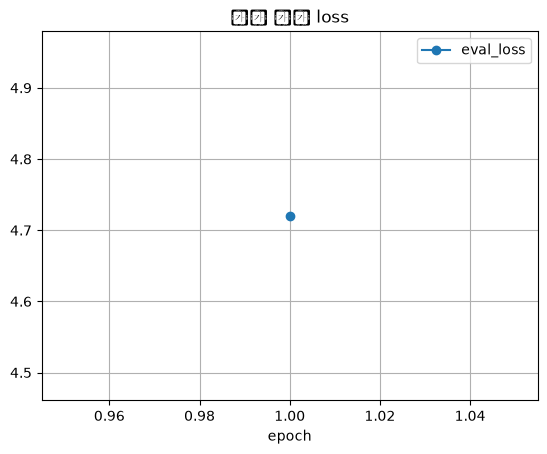

In [7]:
history = pd.DataFrame(trainer.state.log_history)
display(history.tail(10))
if "epoch" in history and "eval_loss" in history:
    history.dropna(subset=["eval_loss"]).plot(
        x="epoch", y="eval_loss", marker="o", grid=True,
        title="내부 검증 loss"
    )
    plt.show()

## 6. 토큰 예측을 답변 구절로 복원

각 토큰 창에서 가능성 높은 시작·끝 위치를 조합합니다. 문단 토큰만 후보로 사용하고, 답변 길이 제한을 적용한 뒤 가장 점수가 높은 구절을 선택합니다. 여기의 점수는 로짓의 합이며 확률로 해석하지 않습니다.

In [8]:
def postprocess_qa(examples, features, start_logits, end_logits,
                   n_best_size=N_BEST_SIZE, max_answer_length=MAX_ANSWER_LENGTH):
    features_by_id = defaultdict(list)
    for feature_idx, feature in enumerate(features):
        features_by_id[feature["example_id"]].append(feature_idx)

    predictions = {}
    for example in examples:
        context = example["context"]
        best_answer, best_score, best_span = "", -float("inf"), None
        for feature_idx in features_by_id[example["id"]]:
            offsets = features[feature_idx]["offset_mapping"]
            starts = np.argsort(start_logits[feature_idx])[-n_best_size:][::-1]
            ends = np.argsort(end_logits[feature_idx])[-n_best_size:][::-1]
            for start_idx in starts:
                for end_idx in ends:
                    if start_idx >= len(offsets) or end_idx >= len(offsets):
                        continue
                    if offsets[start_idx] is None or offsets[end_idx] is None:
                        continue
                    if end_idx < start_idx or end_idx - start_idx + 1 > max_answer_length:
                        continue
                    char_start = offsets[start_idx][0]
                    char_end = offsets[end_idx][1]
                    if not (0 <= char_start < char_end <= len(context)):
                        continue
                    score = float(start_logits[feature_idx][start_idx]
                                  + end_logits[feature_idx][end_idx])
                    if score > best_score:
                        best_answer = context[char_start:char_end]
                        best_score = score
                        best_span = (char_start, char_end)
        predictions[example["id"]] = {
            "answer": best_answer, "span": best_span, "score": best_score
        }
    return predictions

## 7. 공개 검증 세트 평가

공개 검증 세트는 모델 선택에 사용하지 않았습니다. 아래 EM은 정규화한 예측과 정답이 완전히 같은 비율이고, 글자 F1은 정규화한 글자의 겹침입니다. 두 값은 이 노트북의 자체 지표이므로 공식 KorQuAD 리더보드 점수라고 표기하지 않습니다.

In [9]:
prediction_inputs = final_features.remove_columns(["example_id", "offset_mapping"])
prediction_output = trainer.predict(prediction_inputs)
start_logits, end_logits = prediction_output.predictions[:2]
predictions = postprocess_qa(
    final_examples, final_features, start_logits, end_logits
)

def normalize_answer(text):
    text = str(text).lower()
    text = "".join(
        char for char in text
        if not unicodedata.category(char).startswith("P")
    )
    return re.sub(r"\s+", "", text)

def char_f1(prediction, truth):
    p = list(normalize_answer(prediction))
    t = list(normalize_answer(truth))
    if not p or not t:
        return float(p == t)
    overlap = sum((Counter(p) & Counter(t)).values())
    if overlap == 0:
        return 0.0
    precision = overlap / len(p)
    recall = overlap / len(t)
    return 2 * precision * recall / (precision + recall)

def score_one(prediction, gold_answers):
    return (
        max(float(normalize_answer(prediction) == normalize_answer(gold))
            for gold in gold_answers),
        max(char_f1(prediction, gold) for gold in gold_answers),
    )

rows = []
for example in final_examples:
    predicted = predictions[example["id"]]["answer"]
    golds = example["answers"]["text"]
    em, f1 = score_one(predicted, golds)
    rows.append({
        "id": example["id"], "title": example["title"],
        "question": example["question"], "prediction": predicted,
        "gold": golds[0], "em": em, "char_f1": f1,
        "context_length": len(example["context"]),
    })
result_df = pd.DataFrame(rows)
metrics = {
    "normalized_em": float(result_df["em"].mean() * 100),
    "character_f1": float(result_df["char_f1"].mean() * 100),
    "examples": len(result_df),
    "smoke_test": FAST_DEV_RUN,
}
print(metrics)
display(result_df.head(10))
if FAST_DEV_RUN:
    print("FAST_DEV_RUN 결과는 일부 데이터로 학습·평가한 실행 점검 수치입니다.")

{'normalized_em': 4.6875, 'character_f1': 13.034788363278969, 'examples': 64, 'smoke_test': True}


,id,title,question,prediction,gold,em,char_f1,context_length
0,6488411-44-0,김영삼,김영삼 대통령의 정치적 노선 중 가장 마지막의 당은?,김성수·신익희,신한국당,0.0,0.200000,407
1,5782831-2-2,ESP_기타,ESP에서 2014년 단종된 Standard Series의 명맥을 이어 제작되고 있...,E-II,E-II,1.0,1.000000,590
2,6462710-1-2,박대성_(1978년),이명박 정부가 내세운 이론은?,전광우 금융위원장은 9월 8일 산업은행의 리먼 브러더스,금융중심지론,0.0,0.133333,484
3,6482346-1-2,김정남_(조선민주주의인민공화국),쿠알라룸푸르국제공항은 어느나라 공항인가?,"2011년 다음해 인 2012년 초 부터 진행되었으며, 정찰총국",말레이시아,0.0,0.000000,429
4,5905297-0-0,케라톱스,케라톱스로 분류된 첫번째 화석을 발견한 사람은?,오트니엘 찰스 마쉬에게 고용되어 있었는데 마쉬는 같은 해 이 화석을 모식종 케라톱스...,존 벨 해처,0.0,0.046512,512
5,6597540-2-1,캐시_크루즈,막스와 미샤엘이 설립한 공장 중에 이후 모든 제작을 맡게 된 곳은?,VEBs로 통합되었다. 이후 도나우버트,도나우버트,0.0,0.454545,365
6,6657570-6-0,이회창,김대중의 비자금 수사를 유보한 이유중 검찰총장의 고향이 이곳인 것이 수사를 중지시킨...,김태정,호남,0.0,0.000000,474
7,6513625-4-0,러시아_원정,러시아가 전투 태세에 들어가면서 벌어지는 8월의 전투는 무엇입니까?,스몰렌스크 전투가 벌어지게 되었다. 데 톨리는 스몰렌스크를 중심으로 방어전을 전개했...,스몰렌스크 전투,0.0,0.280000,490
8,6584295-5-0,쇼와_천황,히로히토가 가쿠슈인의 초등과에 입학한 년도는?,장전부(掌典部,1908년,0.0,0.000000,533
9,6556751-15-2,중화인민공화국의_법,일부 학자들은 상사법의 특수성에 비추어 무엇을 제정할 필요가 있다고 주장하는가?,상사법이 가지는 특수성에 비추어 상법총칙,상법총칙,0.0,0.363636,407


FAST_DEV_RUN 결과는 일부 데이터로 학습·평가한 실행 점검 수치입니다.


## 8. 오류 분석

틀린 사례와 문단 길이에 따른 성능을 봅니다. 좋은 보고서는 숫자만 제시하지 않고, 잘못 추출한 이유를 사례와 연결합니다.

In [10]:
length_bins = pd.cut(
    result_df["context_length"],
    bins=[0, 500, 1000, 2000, float("inf")],
    labels=["500자 이하", "501~1000자", "1001~2000자", "2000자 초과"],
)
by_length = result_df.groupby(length_bins, observed=True).agg(
    건수=("id", "count"),
    EM=("em", "mean"),
    글자_F1=("char_f1", "mean"),
)
display(by_length)
display(result_df.loc[result_df["em"] == 0,
                      ["title", "question", "gold", "prediction", "char_f1"]]
        .sort_values("char_f1").head(20))

,건수,EM,글자_F1
context_length,,,
500자 이하,38,0.026316,0.127464
501~1000자,26,0.076923,0.134563


,title,question,gold,prediction,char_f1
3,김정남_(조선민주주의인민공화국),쿠알라룸푸르국제공항은 어느나라 공항인가?,말레이시아,"2011년 다음해 인 2012년 초 부터 진행되었으며, 정찰총국",0.0
6,이회창,김대중의 비자금 수사를 유보한 이유중 검찰총장의 고향이 이곳인 것이 수사를 중지시킨...,호남,김태정,0.0
8,쇼와_천황,히로히토가 가쿠슈인의 초등과에 입학한 년도는?,1908년,장전부(掌典部,0.0
15,테드_번디,테드 번디가 3살까지 살았던 곳은?,필라델피아,엘리너 코웰,0.0
16,바이오쇼크,2K 게임즈가 게임에서 생기는 문제들에 대하여 언급한 곳은?,취소 툴 FAQ,하드 디스크 오류,0.0
12,젭_스튜어트,젭 스튜어트가 태어난 패트릭 카운티의 대농장은?,로렐 힐,아치볼트,0.0
11,아가씨,영화 아가씨의 배경시대는?,일제강점기,복순,0.0
10,이회창,1999년 11월 이회창이 기자들을 초청하여 파티를 연 장소는 누구의 아파트였나?,딸,신천동 7-28 현대타워,0.0
28,러시아_원정,프랑스의 러시아 원정 당시 러시아군을 이끌었던 지휘자는?,바클레이 데 톨리,흐로드나와 카우나스,0.0
25,원자력진흥종합계획,지원체제를 강화하기 위해 추진하는 것은?,"스타프로젝트, X-프로젝트",국제 교육훈련,0.0


## 9. 새로운 문단과 질문 직접 입력

다음 함수는 긴 문단에도 토큰 창을 적용합니다. 결과의 답변 위치를 사용해 원문 안의 근거를 강조합니다. 직접 작성한 예시 문단으로 동작을 확인하고 질문·문단을 자유롭게 바꿔보세요.

In [11]:
def answer_question(question, context, model=trainer.model,
                    tokenizer=tokenizer):
    if not question.strip() or not context.strip():
        raise ValueError("질문과 문단을 모두 입력하세요.")
    encoded = tokenizer(
        question.strip(), context,
        truncation="only_second",
        max_length=MAX_LENGTH,
        stride=DOC_STRIDE,
        return_overflowing_tokens=True,
        return_offsets_mapping=True,
        return_token_type_ids=False,
        padding="max_length",
        return_tensors="pt",
    )
    sequence_ids = [encoded.sequence_ids(i)
                    for i in range(encoded["input_ids"].shape[0])]
    offsets = encoded.pop("offset_mapping").tolist()
    encoded.pop("overflow_to_sample_mapping", None)
    device = next(model.parameters()).device
    model_inputs = {key: value.to(device) for key, value in encoded.items()}
    model.eval()
    with torch.no_grad():
        output = model(**model_inputs)
    start_scores = output.start_logits.cpu().numpy()
    end_scores = output.end_logits.cpu().numpy()

    features = []
    for window_idx, window_offsets in enumerate(offsets):
        features.append({
            "example_id": "user_input",
            "offset_mapping": [
                offset if sequence_ids[window_idx][token_idx] == 1 else None
                for token_idx, offset in enumerate(window_offsets)
            ],
        })
    example = [{"id": "user_input", "context": context}]
    return postprocess_qa(example, features, start_scores, end_scores)["user_input"]

def show_highlight(context, span):
    if span is None:
        print("답변 구절을 찾지 못했습니다.")
        return
    import html
    left = html.escape(context[:span[0]])
    middle = html.escape(context[span[0]:span[1]])
    right = html.escape(context[span[1]:])
    display(HTML(left + "<mark>" + middle + "</mark>" + right))

new_context = (
    "도서관은 평일 오전 9시부터 오후 8시까지 운영한다. "
    "토요일에는 오전 10시부터 오후 5시까지 운영하며, 일요일과 공휴일에는 휴관한다."
)
new_question = "토요일 도서관 운영 시간은 언제인가요?"
answer = answer_question(new_question, new_context)
print("질문:", new_question)
print("예측 답변:", answer["answer"])
show_highlight(new_context, answer["span"])

질문: 토요일 도서관 운영 시간은 언제인가요?
예측 답변: 평일


## 10. 모델의 문제점과 개선 방법

- **긴 문서:** 현재 모델은 한 번에 모든 문단을 읽지 못합니다. 문단 검색을 앞단에 붙이고, 창 길이와 겹침 길이를 비교합니다.
- **답이 없는 질문:** KorQuAD 1.0의 기본 설정에는 답변 불가 사례가 없으므로, 별도 데이터를 추가하고 거절 기준을 검증해야 합니다.
- **실제 문서와의 차이:** 위키백과 문단에서 학습한 모델을 안내문·매뉴얼에 적용할 때는 해당 분야의 정답 데이터로 추가 평가·파인튜닝합니다.

오류 분석 표와 직접 입력 결과를 근거로 어떤 문제가 실제로 나타났는지 구분해 기록합니다. 위 개선안의 효과는 아직 검증되지 않았습니다.